# 01 Explore the Hillstrom email test

In 2008 an online retailer ran a two week email test on 64,000 customers who had bought something in the past year. Each customer was randomly put into one of three groups:

- **control**: no email
- **mens_email**: an email featuring men's merchandise
- **womens_email**: an email featuring women's merchandise

Outcomes: whether the customer visited the site, whether they bought, and how much they spent.

Before looking at results, this notebook checks that the test itself can be trusted: the groups are the expected size and look alike before treatment.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from exptoolkit.data import load_hillstrom
from exptoolkit.checks import sample_ratio_check, standardized_mean_diff

pd.set_option("display.float_format", "{:.4f}".format)
df = load_hillstrom()
df.shape

(64000, 14)

In [2]:
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,arm,treated
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000,womens_email,1
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000,control,0
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000,womens_email,1
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000,mens_email,1
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000,womens_email,1


## 1. Are the groups the size we planned?

The plan was an equal three way split. A sample ratio mismatch (groups noticeably bigger or smaller than planned) usually means something went wrong in assignment or tracking, and it can bias every result downstream.

In [3]:
srm = sample_ratio_check(df)
srm

{'counts': {'control': 21306, 'mens_email': 21307, 'womens_email': 21387},
 'expected': {'control': 21333.3,
  'mens_email': 21333.3,
  'womens_email': 21333.3},
 'chi2': 0.20253125000000002,
 'p_value': 0.9036929575604196}

The three groups are within about 80 customers of each other and the p-value is high, so there is no sign of a sample ratio mismatch.

## 2. Do the groups look alike before the email?

If randomization worked, customer history should be about the same in every group. The standardized mean difference (SMD) puts each covariate on the same scale. Values under 0.1 are usually considered balanced.

In [4]:
covariates = ["recency", "history", "mens", "womens", "newbie"]
df.groupby("arm")[covariates].mean()

,recency,history,mens,womens,newbie
arm,,,,,
control,5.7497,240.8827,0.5532,0.5476,0.5020
mens_email,5.7736,242.8359,0.5509,0.5514,0.5015
womens_email,5.7678,242.5366,0.5489,0.5501,0.5032


In [5]:
standardized_mean_diff(df, covariates)

arm,mens_email,womens_email
covariate,,
history,0.0076,0.0065
mens,-0.0046,-0.0086
newbie,-0.0009,0.0026
recency,0.0068,0.0052
womens,0.0076,0.0049


In [6]:
pd.crosstab(df["arm"], df["channel"], normalize="index")

channel,Multichannel,Phone,Web
arm,,,
control,0.1223,0.4378,0.4399
mens_email,0.1209,0.4337,0.4454
womens_email,0.1206,0.4420,0.4374


In [7]:
pd.crosstab(df["arm"], df["zip_code"], normalize="index")

zip_code,Rural,Surburban,Urban
arm,,,
control,0.1473,0.4518,0.4009
mens_email,0.1522,0.4459,0.4019
womens_email,0.1487,0.4512,0.4001


Every SMD is far below 0.1, and purchase channel and area type are split almost identically across groups. Randomization looks clean, so differences in outcomes can be read as effects of the email.

## 3. First look at outcomes

These are raw averages only. Confidence intervals and significance tests come in notebook 03.

In [8]:
outcomes = df.groupby("arm")[["visit", "conversion", "spend"]].mean()
outcomes

,visit,conversion,spend
arm,,,
control,0.1062,0.0057,0.6528
mens_email,0.1828,0.0125,1.4226
womens_email,0.1514,0.0088,1.0772


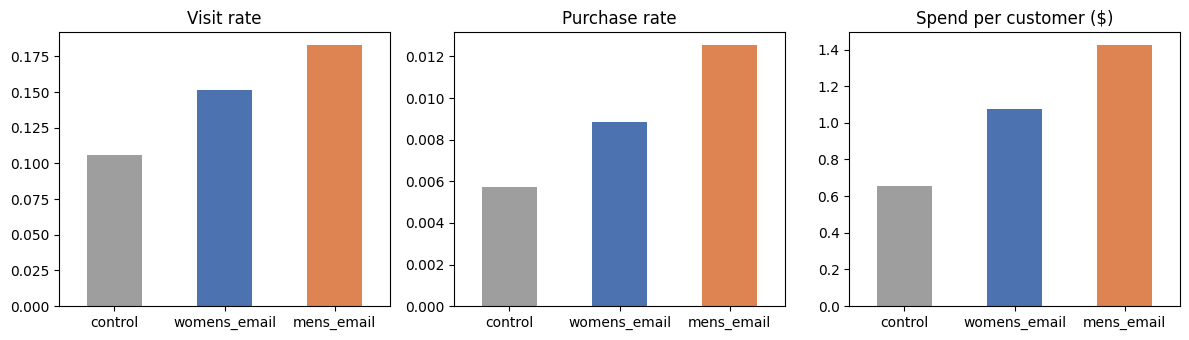

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
labels = {"visit": "Visit rate", "conversion": "Purchase rate", "spend": "Spend per customer ($)"}
order = ["control", "womens_email", "mens_email"]
for ax, col in zip(axes, labels):
    outcomes.loc[order, col].plot.bar(ax=ax, color=["#9e9e9e", "#4c72b0", "#dd8452"])
    ax.set_title(labels[col])
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

Spend is very skewed: fewer than 1% of customers bought anything, so almost every value is zero. Looking only at buyers shows whether the email changed how much people spent, or just how many people bought.

In [10]:
df[df["conversion"] == 1].groupby("arm")["spend"].agg(["count", "mean", "median"])

,count,mean,median
arm,,,
control,122,114.0027,88.3650
mens_email,267,113.5269,66.9800
womens_email,189,121.8948,94.7100


## What this tells us so far

- The test is trustworthy: group sizes match the plan and the groups look alike before treatment.
- Both emails appear to lift visits and purchases over no email. The men's email shows the larger lift on all three outcomes.
- Average spend among buyers is similar across groups, so most of the extra revenue seems to come from more people buying, not from bigger orders.
- With under 1% of customers buying, purchase and spend estimates will be noisy. Notebook 02 looks at how large a test needs to be to detect lifts this small, and notebook 03 puts confidence intervals on these numbers.